# Install Ollama and run , Install all dependencies

In [ ]:
!apt-get install zstd
!curl -fsSL https://ollama.com/install.sh | sh

In [ ]:
# Starte Ollam a server and download model
import subprocess

ollama_prs = subprocess.Popen(["ollama","serve"],
                              stdout=subprocess.PIPE,
                              stderr=subprocess.PIPE)

# Install all dependecies for langraph
!pip install langchain
!pip install langchain-core
!pip install langchain-community
!pip install langchain-ollama
!pip install langgraph

# Download model
!ollama pull llama3.2:1b

# Langgraph with multiple node

In [ ]:
!ollama list

NAME           ID              SIZE      MODIFIED       
llama3.2:1b    baf6a787fdff    1.3 GB    15 seconds ago    


In [ ]:
# Create a model
from langchain_ollama import ChatOllama
llm = ChatOllama(model="llama3.2:1b", temperature=0)

In [ ]:
# Create a state for nodes
from pydantic import BaseModel
class SupportTicket(BaseModel):
  query : str
  intent : str = None
  data : str = None
  response : str = None
  nodes_ran : list = []

In [ ]:
def classifier_node(state : SupportTicket):
  user_msg = state.query
  state.nodes_ran.append("Classifier Node")

  prompt = f"""
  Classify this support query.

  Query : {user_msg}

  Return exaclty one word:
    billing
    technical
    shipping
  """

  result = llm.invoke(prompt)

  # Update state
  state.intent = result.content.strip().lower()
  return state



In [ ]:
def billing_node(state: SupportTicket):
  # call your database query and fetch the data
  data = """
         customer invoice is pending
         Amount due : 5$
         Due Date : 20 June
         """
  state.data = data
  state.nodes_ran.append("Billing Node")
  return state

In [ ]:
def technical_node(state: SupportTicket):
  data = """
        Common troublshootings
        1. Restart application
        2. clear cache
        3. Re-Login
  """
  state.data = data
  state.nodes_ran.append("Technical Node")
  return state

In [ ]:
def shipping_node(state: SupportTicket):
  data = """
        Packate is in transit,
        Expected delivery : Tomorrow
  """
  state.data = data
  state.nodes_ran.append("Shipping Node")
  return state


In [ ]:
def responder_node(state : SupportTicket):
  prompt = f"""
            You are a professional customer support agent
            respond user accordingly

            User Query : {state.query}

            context : {state.data}

            generate a helpfull response
            """
  response = llm.invoke(prompt)
  state.response = response
  state.nodes_ran.append("Responder Node")
  return state


In [ ]:
# Router takes state as input but returns string -- this string represents which node to run next
def router(state : SupportTicket):
  intent = state.intent
  state.nodes_ran.append("Router Function")
  if "bill" in intent:
    return "biller"
  elif "tech" in intent:
    return "technic"
  return "shipper"

In [ ]:
# Build a graph
from langgraph.graph import StateGraph, END

# Initialize the graph with state info
builder = StateGraph(SupportTicket)

# add all nodes
builder.add_node("classify", classifier_node)
builder.add_node("billing",billing_node)
builder.add_node("tech", technical_node)
builder.add_node("shipping",shipping_node)
builder.add_node("responder",responder_node)

# add all edges -- based onm problem statement and logic

## Set entry point
builder.set_entry_point("classify")

# add conditional edge -- function
builder.add_conditional_edges(
    "classify",
    router,
    {
        "biller" : "billing",
        "technic" : "tech",
        "shipper" : "shipping"
    }
)

builder.add_edge("billing", "responder")
builder.add_edge("tech", "responder")
builder.add_edge("shipping", "responder")
builder.add_edge("responder",END)

graph = builder.compile()

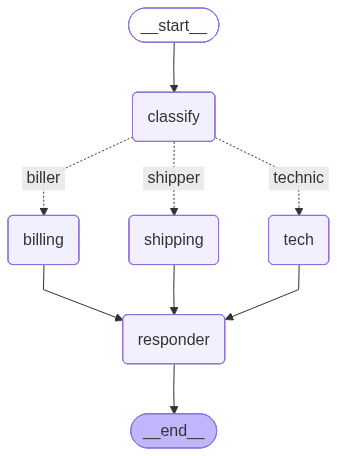

In [ ]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [ ]:
# run graph -- shipping
sample_state = SupportTicket(query="I haven't recieved my package yet")

result = graph.invoke(sample_state)

print(result)
print(result["nodes_ran"])
print(result["response"].content)


{'query': "I haven't recieved my package yet", 'intent': 'i would classify the support query as "billing".', 'data': '\n         customer invoice is pending \n         Amount due : 5$\n         Due Date : 20 June\n         ', 'response': AIMessage(content="I'm so sorry to hear that you haven't received your package yet. \n\nFirstly, I'd like to confirm that your order was indeed placed on our website and is still pending for shipment. Our system shows that the invoice is also pending for payment.\n\nAs per our records, the estimated delivery date for this package is June 20th. However, please note that this is an estimate and may vary depending on various factors such as customs clearance and shipping carrier.\n\nTo expedite the process, I'd like to offer you a few options:\n\n1. **Track your package**: You can check the status of your package by logging into our website or mobile app. This will give you an update on when it's expected to arrive.\n2. **Contact us directly**: If you hav

In [ ]:
# run graph -- technical
sample_state = SupportTicket(query="how do i reset this system")

result = graph.invoke(sample_state)

print(result)
print(result["nodes_ran"])
print(result["response"].content)

{'query': 'how do i reset this system', 'intent': 'i would classify this support query as "billing".', 'data': '\n         customer invoice is pending \n         Amount due : 5$\n         Due Date : 20 June\n         ', 'response': AIMessage(content="I'm happy to assist you with your query.\n\nHowever, I need to clarify that as a customer support agent, I'll be providing guidance on how to reset the system, but I won't be able to directly access or modify any internal systems. But don't worry, I can guide you through the process of resetting the system and provide some helpful tips along the way.\n\nTo reset your system, please follow these steps:\n\n1. **Check if there are any pending updates**: Ensure that your device is up-to-date with the latest software and security patches.\n2. **Clear browser cache and cookies**: Clearing your browser's cache and cookies can help resolve any issues related to outdated data or corrupted files.\n3. **Try a system reset**: If you're using a mobile 

In [ ]:
# run graph -- billing
sample_state = SupportTicket(query="can i get a copy of invoice")

result = graph.invoke(sample_state)

print(result)
print(result["nodes_ran"])
print(result["response"].content)

{'query': 'can i get a copy of invoice', 'intent': 'i would classify this support query as "billing".', 'data': '\n         customer invoice is pending \n         Amount due : 5$\n         Due Date : 20 June\n         ', 'response': AIMessage(content='I\'m happy to assist you with your query.\n\nAs the customer, I\'d like to request a copy of my pending invoice. However, since it\'s still pending and not yet processed, I won\'t be able to receive an actual physical copy of the invoice.\n\nThat being said, I can provide you with some options to obtain a digital copy or more information about your account.\n\nYou can try contacting me directly via this chat platform to request a digital copy of your invoice. Alternatively, you can also check our website for any updates on your pending order and look for an "Invoice" section where you can download a digital copy.\n\nAdditionally, I\'d like to inform you that we have a 3-day processing time frame before the due date. If you\'re unable to r